In [3]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Found 624 matching curve CSVs in /workspaces/AFM-plots_Jython_exports/csv_data. Plotting 5.


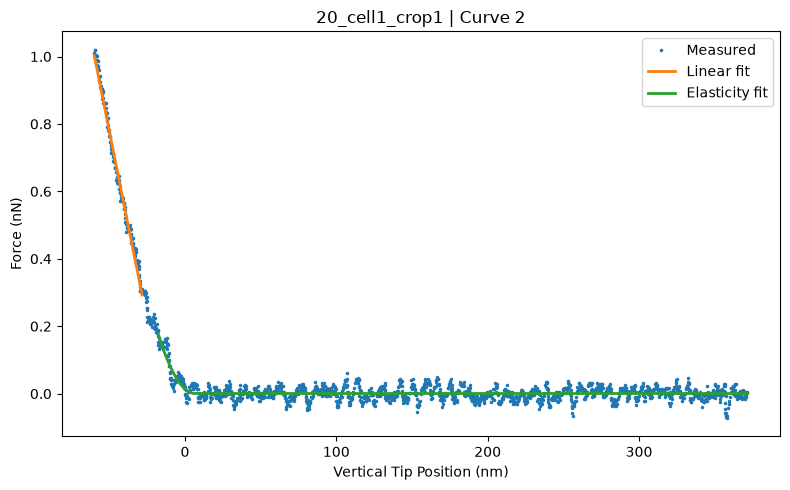

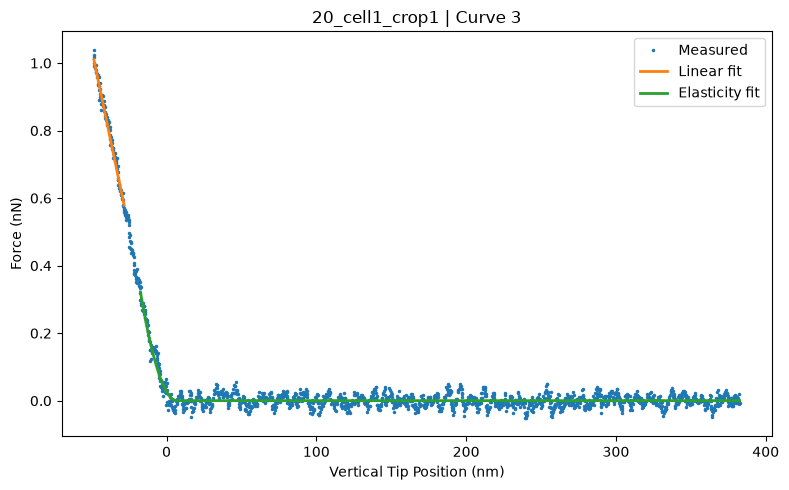

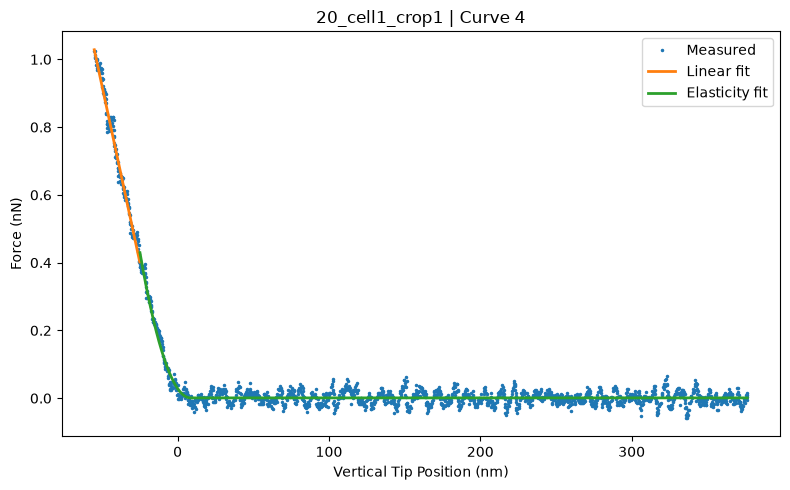

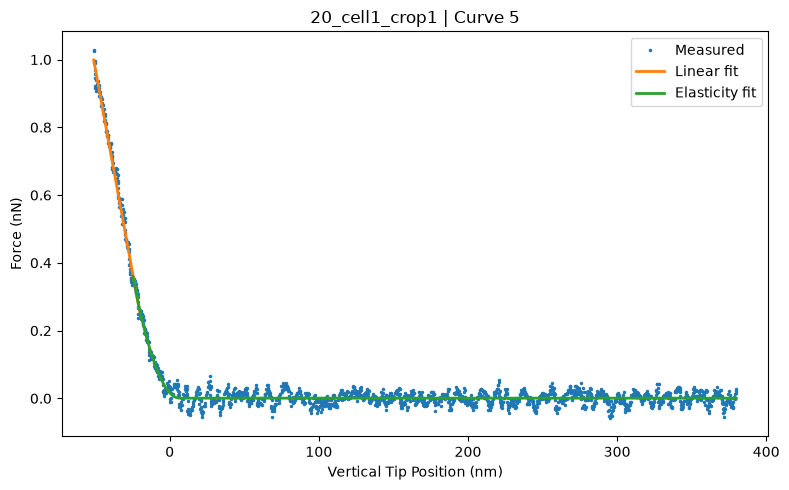

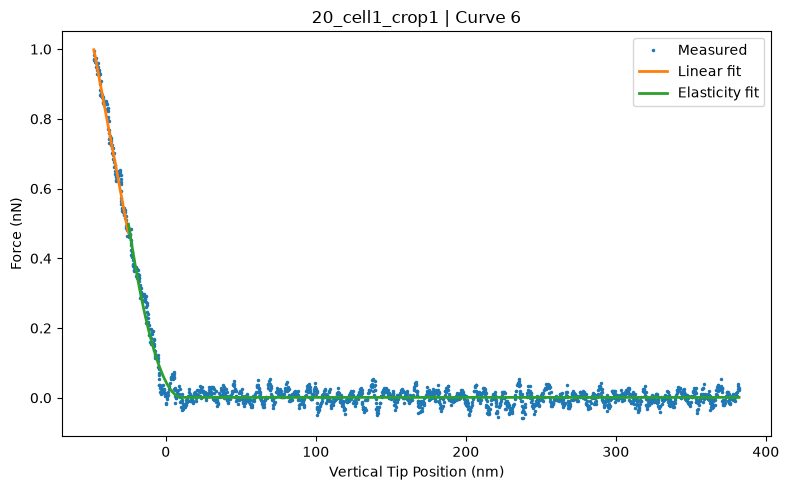

In [4]:
import csv
import math
import re
from pathlib import Path
import matplotlib.pyplot as plt

# Edit these settings to select which curves you want to inspect.
# Leave filters as None to include every matching folder/curve.
FOLDER_FILTER = None   # e.g. "Live_cell1_crop4"
CURVE_FILTER = None    # e.g. 26
MAX_PLOTS = 5         # Increase this number, or use None for all plots.

# In GitHub Codespaces the CSV exports are inside csv_data/<cell_crop>/.
# Search here and in parent directories in case the notebook starts elsewhere.
root_candidates = [Path.cwd(), *list(Path.cwd().parents)[:3]]
data_folder = next(
    (root / "csv_data" for root in root_candidates if (root / "csv_data").is_dir()),
    None,
)
if data_folder is None:
    raise FileNotFoundError(
        "Could not find a csv_data directory. Run this notebook in the "
        "repository folder, or one of its subfolders."
    )

files = sorted(data_folder.rglob("AFM_fit_points_curve_*.csv"))
if FOLDER_FILTER:
    files = [p for p in files if p.parent.name == FOLDER_FILTER]

# The filename has the intended curve number. In a few legacy fit-point
# exports the internal curve_number column was incorrectly assigned.
def curve_number_from_name(path):
    match = re.search(r"AFM_fit_points_curve_(\d+)_position_", path.name)
    return int(match.group(1)) if match else None

if CURVE_FILTER is not None:
    files = [p for p in files if curve_number_from_name(p) == int(CURVE_FILTER)]

if not files:
    print("No matching curve CSVs found in", data_folder)
else:
    selected_files = files if MAX_PLOTS is None else files[:MAX_PLOTS]
    print(
        f"Found {len(files)} matching curve CSVs in {data_folder}. "
        f"Plotting {len(selected_files)}."
    )

    def valid_points(rows, x_column, y_column, used_column=None):
        points = []
        for row in rows:
            if used_column is not None and row.get(used_column) != "1":
                continue
            try:
                x = float(row[x_column])
                y = float(row[y_column])
            except (KeyError, ValueError, TypeError):
                continue
            if math.isfinite(x) and math.isfinite(y):
                points.append((x, y))
        if used_column is not None:
            points.sort(key=lambda p: p[0])
        return points

    for file in selected_files:
        with file.open(encoding="utf-8-sig", newline="") as f:
            rows = list(csv.DictReader(f))
        if not rows:
            print("Skipped empty file:", file)
            continue

        measured = valid_points(rows, "x_nm", "measured_y_nN")
        if not measured:
            print("Skipped file without valid measured points:", file)
            continue

        plt.figure(figsize=(8, 5))
        x, y = zip(*measured)
        plt.plot(x, y, ".", markersize=3, label="Measured")

        for y_column, flag, label in [
            ("linear_fit_y_nN", "linear_fit_used", "Linear fit"),
            ("elasticity_fit_y_nN", "elasticity_fit_used", "Elasticity fit"),
        ]:
            points = valid_points(rows, "x_nm", y_column, flag)
            if points:
                fit_x, fit_y = zip(*points)
                plt.plot(fit_x, fit_y, linewidth=2, label=label)

        curve_num = curve_number_from_name(file)
        plt.title(f"{file.parent.name} | Curve {curve_num}")
        plt.xlabel("Vertical Tip Position (nm)")
        plt.ylabel("Force (nN)")
        plt.legend()
        plt.tight_layout()
        plt.show()
